In [1]:
import pyC2C as c2c
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
# load fid or ms data
raw_data = c2c.load_file('sample_data/shimadzu_C2C005.qgd')
raw_data.getBPC() 

0
10000
20000
30000
40000
50000
60000
70000
80000
90000
100000
Number of MS1 scans: 106680


### Load results data frame

In [ ]:
results_df = pd.read_csv('sample_data/c2c_005_MSscans.csv', sep=',')
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...


### Molecule m/z
- loop through MS scans and get last four m/z values
- add m/z with highest intensity to data frame

In [4]:
molecul_mz = c2c.getMoleculeMZ(results_df=results_df)

# add to data frame
results_df['Molecule m/z'] = molecul_mz
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20


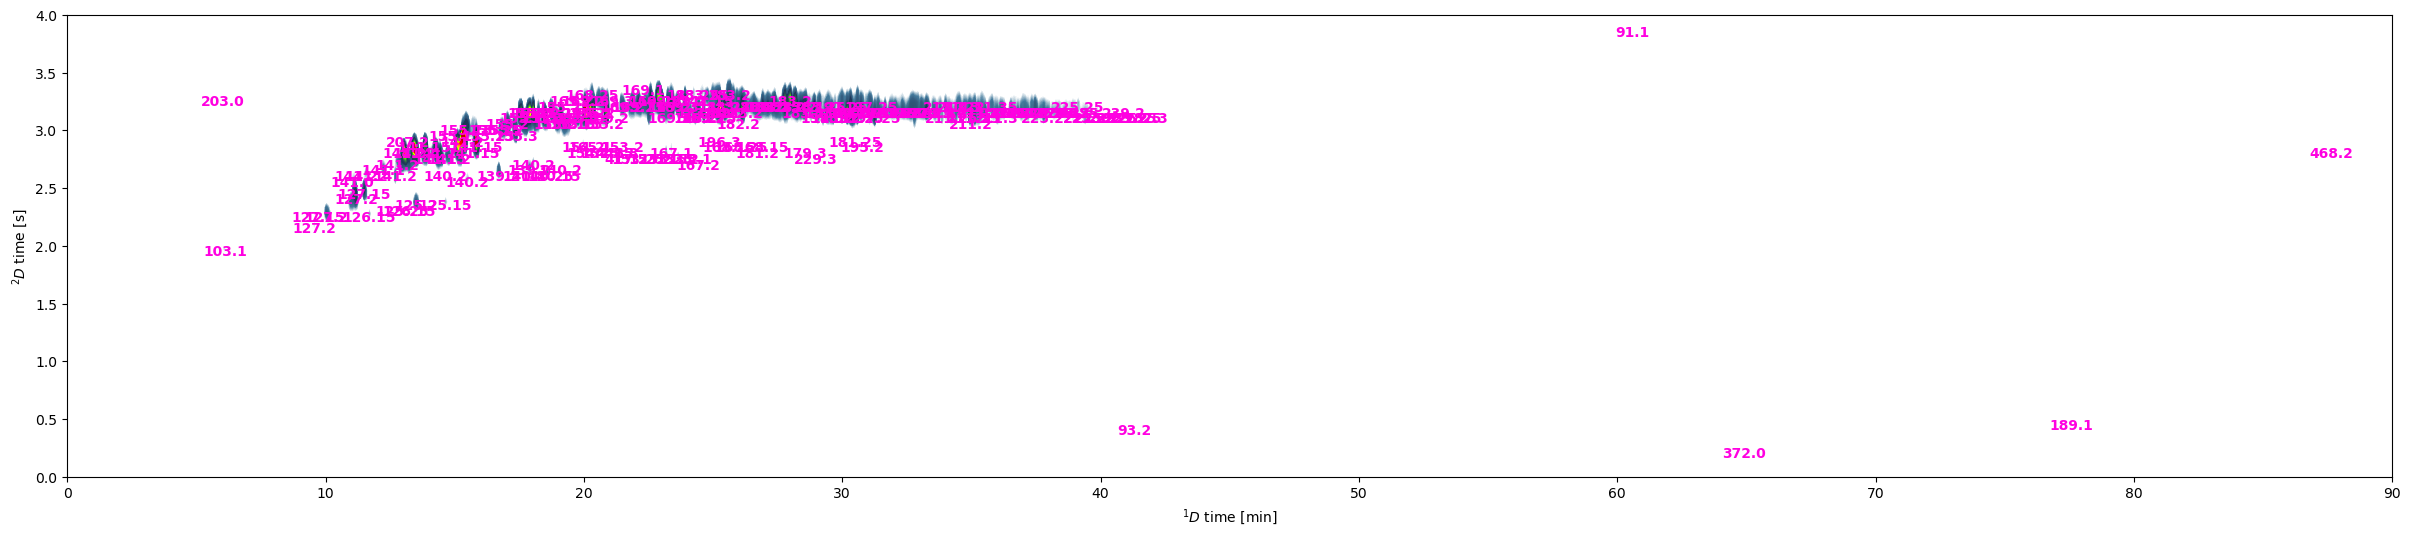

In [5]:
# create scatter plot with molecule m/z
fig, ax = plt.subplots(figsize=(30, 6))

xmin = 0
xmax = 90
ymin = 0
ymax = 4

c2c.plot2d(fig, ax, 
           raw_data.rt, raw_data.bpc,
           mod_time= 4, 
           shift = 1,
           solvent_cut= 0,
           color_range=(8, 80),
           cbar = False)

for i in range(len(results_df)):
    row = results_df.iloc[i, :]

    if xmin <= row['RT 1d (min)'] <= xmax and ymin <= row['RT 2d (s)'] <= ymax:

        ax.text(row['RT 1d (min)'], row['RT 2d (s)'], 
                s= row['Molecule m/z'],
                va = 'center', ha='center',
                color="#FF00E1", fontdict=dict({'fontweight': 'bold'}))
        
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

plt.show()

### Get carbon number from m/z

In [6]:
# used dictionary in C2C package
display(c2c.dictionaries.molecule_mz_cnum) # cnum, minimum (DBE 4), maximum (DBE 0)

{7: [91, 99],
 8: [105, 113],
 9: [119, 127],
 10: [133, 141],
 11: [147, 155],
 12: [161, 169],
 13: [175, 183],
 14: [189, 197],
 15: [203, 211],
 16: [217, 225],
 17: [231, 239],
 18: [245, 253]}

In [7]:
results_df['CNum (m/z)'] = c2c.getCNUM_from_MoleculeMZ(results_df['Molecule m/z'], mz_cnum_dict=c2c.dictionaries.molecule_mz_cnum)
results_df.head()

,Time,RT 1d (min),RT 2d (s),Height,Time Cluster ID,MS1,Molecule m/z,CNum (m/z)
0,6.1158,6.10,1.95,21049.0,1,66.05:7.42 67.0:6.38 67.1:25.33 67.15:9.37 67....,103.10,-1
1,6.0708,6.03,3.25,6014.0,2,65.0:25.09 66.0:20.43 66.1:8.64 67.1:50.38 68....,203.00,15
2,9.5858,9.57,2.15,26802.0,3,63.0:5.04 65.0:14.04 66.0:5.91 66.1:6.08 66.15...,127.20,9
3,9.7208,9.70,2.25,13021.0,4,65.0:14.3 66.1:5.15 66.15:13.88 66.2:5.51 66.2...,127.15,9
4,10.0542,10.03,2.25,82421.0,5,65.0:6.14 66.0:7.06 67.05:5.31 67.1:8.11 67.2:...,127.20,9


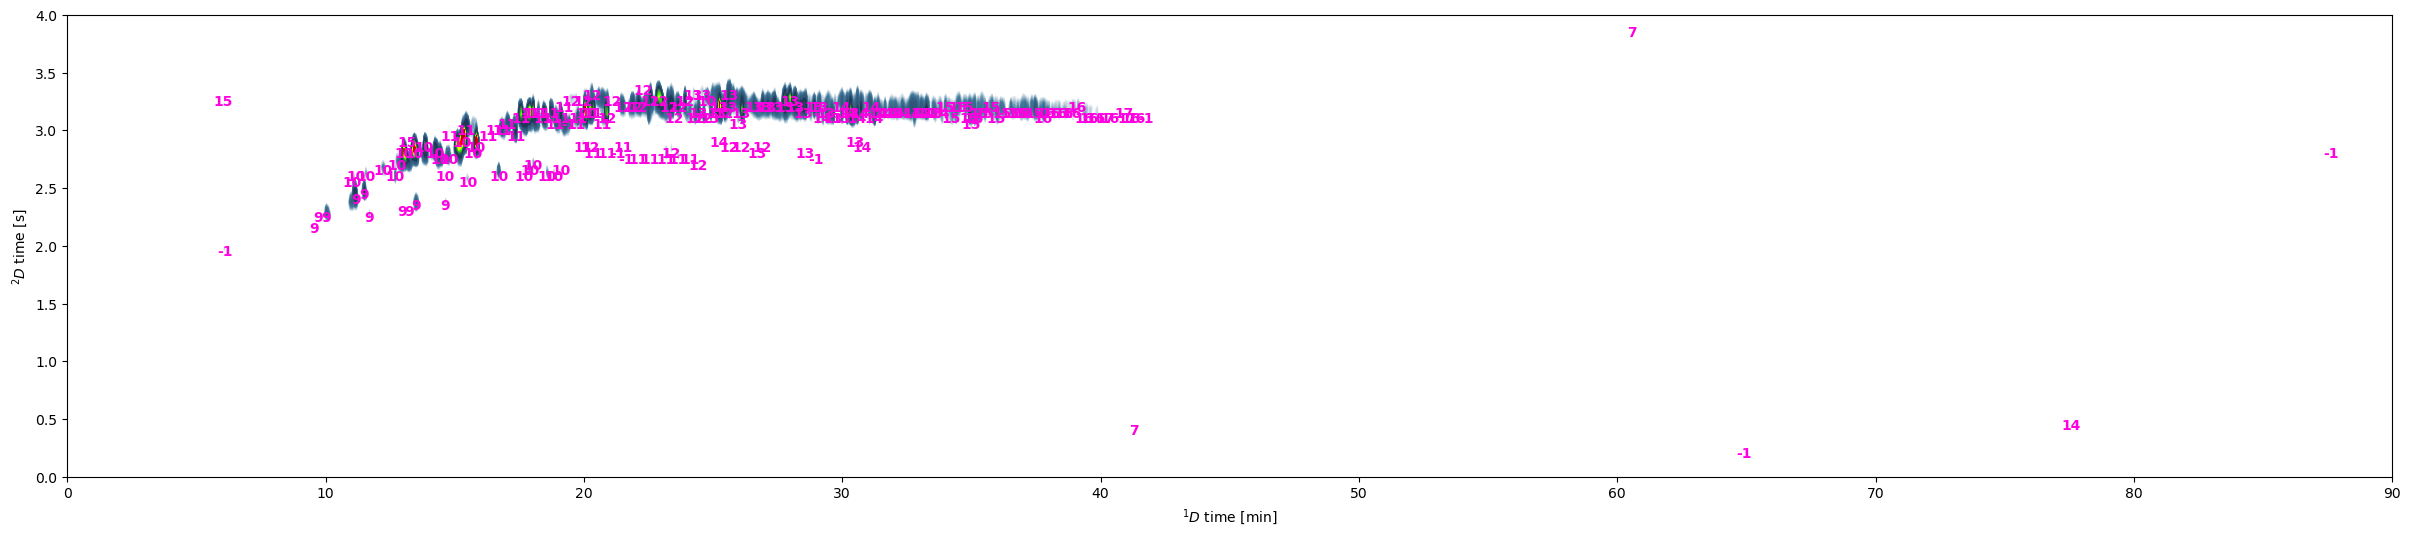

In [8]:
# create scatter plot with molecule m/z carbon number
fig, ax = plt.subplots(figsize=(30, 6))

xmin = 0
xmax = 90
ymin = 0
ymax = 4

c2c.plot2d(fig, ax, 
           raw_data.rt, raw_data.bpc,
           mod_time= 4, 
           shift = 1,
           solvent_cut= 0,
           color_range=(8, 80),
           cbar = False)

for i in range(len(results_df)):
    row = results_df.iloc[i, :]

    if xmin <= row['RT 1d (min)'] <= xmax and ymin <= row['RT 2d (s)'] <= ymax:

        ax.text(row['RT 1d (min)'], row['RT 2d (s)'], 
                s= row['CNum (m/z)'],
                va = 'center', ha='center',
                color="#FF00E1", fontdict=dict({'fontweight': 'bold'}))
        
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)

plt.show()

In [ ]:
# export data frame
results_df.to_csv('sample_data/C2C-005_results.csv', sep=',', index=False)